# PINN Model — TEMA Type A + Udata (LMTD)

Built **from scratch** using `data.csv`, fixed TEMA geometry, LMTD-based **Udata**, and differentiable TEMA rating physics.

## Model definition

A neural network maps operating inputs to heat-exchanger outputs:

$$
(m_a, m_w, T_{a,in}, T_{w,in}) \;\longrightarrow\; (U,\, T_{a,out},\, T_{w,out})
$$

Training minimizes:

$$
\mathcal{L} = \mathcal{L}_{\mathrm{data}} + \lambda_{\mathrm{phys}}\,\mathcal{L}_{\mathrm{physics}} + \lambda_{\mathrm{bnd}}\,\mathcal{L}_{\mathrm{bounds}}
$$

| Piece | Role |
|--------|------|
| **Data** | Fit **Udata** (LMTD), dataset `Taout`, `Twout` |
| **Physics** | Soft match to TEMA film `U_phys` + E-NTU outlets |
| **Bounds** | Soft thermodynamic constraints (ReLU hinges) |
| **Geometry** | TEMA Type A, 160 tubes, L=6 m, triangular pitch |

**U target:** `Udata = Qavg / (A · LMTD)` — not CSV `U_actual`.


## 1. Libraries and data


In [1]:
# Libraries + load data.csv
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
torch.manual_seed(42)
np.random.seed(42)

DATA_DIR = Path(r"c:\Users\krish\JBS Tech\Heat exchanger Digital Twin\Serial Model")
data_path = DATA_DIR / "data.csv"
if not data_path.exists():
    data_path = Path("data.csv")
if not data_path.exists():
    raise FileNotFoundError("data.csv not found")

df_raw = pd.read_csv(data_path, header=1)
if "State" in df_raw.columns:
    df_raw = df_raw[df_raw["State"].astype(str).str.startswith("Case")].copy()

cols = {
    "Hot Air flow in Shell": "m_air_kgh",
    "Cooling water flow in Tubes": "m_water_kgh",
    "1 - Temperature": "T_air_in",
    "3 - Temperature": "T_water_in",
    "2 - Temperature": "T_air_out",
    "4 - Temperature": "T_water_out",
    "E-100 - Overall U": "U_actual",
}
df = df_raw[list(cols.keys())].rename(columns=cols).copy()
for c in df.columns:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df = df.dropna().reset_index(drop=True)

df["m_air"] = df["m_air_kgh"] / 3600.0
df["m_water"] = df["m_water_kgh"] / 3600.0

print("Loaded:", data_path.resolve())
print("Shape:", df.shape)
print(df.head())


Loaded: C:\Users\krish\JBS Tech\Models\Heat exchanger Digital Twin\Serial Model\data.csv
Shape: (7526, 9)
   m_air_kgh  m_water_kgh  T_air_in  T_water_in  T_air_out  T_water_out  \
0    10000.0      10000.0     100.0        25.0      69.25        32.12   
1    10000.0      10000.0     150.0        25.0      98.14        37.10   
2    10000.0      10000.0     200.0        25.0     126.70        42.24   
3    10000.0      10000.0     250.0        25.0     155.00        47.50   
4    10000.0      10000.0     300.0        25.0     183.10        52.89   

   U_actual     m_air   m_water  
0     26.67  2.777778  2.777778  
1     27.33  2.777778  2.777778  
2     27.94  2.777778  2.777778  
3     28.49  2.777778  2.777778  
4     28.98  2.777778  2.777778  


## 2. TEMA geometry, properties, LMTD Udata, and physics

**Fixed geometry (TEMA Type A, 2-pass, triangular pitch)**
- `N = 160`, `L = 6 m`, `d_o = 0.020 m`, `P = 0.050 m`
- `De = 4(0.86 P² − π d_o²/4)/(π d_o)`
- `A = N · π · d_o · L`

**Inlet pressures (absolute, fixed for every row)**
- Air (shell side): `P_AIR_IN = 1.5 atm`
- Water (tube side): `P_WATER_IN = 2 atm`
- Used in the fluid properties: air density (ideal gas), water density (compressibility) and the water liquid range (boiling point at `P_WATER_IN`)

**Udata (LMTD)**
$$
LMTD = \frac{\Delta T_1-\Delta T_2}{\ln(\Delta T_1/\Delta T_2)},\quad
Udata = \frac{Q_{avg}}{A\cdot LMTD}
$$


In [2]:
# TEMA Type A geometry + fluid properties + Udata (LMTD) + torch physics

# ----- Fixed Geometry -----
N_TUBES = 160
N_PASSES = 2
L_TUBE = 6.0
D_O = 0.020
WALL_THICKNESS = 0.002
PITCH = 0.050
D_S = 0.387
B_BAFFLE = 0.8
K_WALL = 45.0
R_FI = 0.00015
R_FO = 0.00035

# Inner diameter of tube (meters)
D_I = D_O - 2.0 * WALL_THICKNESS

# Total outer surface area for heat transfer (m^2)
A_O_TOTAL = N_TUBES * (math.pi * D_O * L_TUBE)
A_o_total = A_O_TOTAL  # Alternative variable name for clarity

# Number of tubes per pass
N_TUBES_PER_PASS = N_TUBES / N_PASSES

# Total flow area inside tubes (m^2)
A_FLOW_TUBE = N_TUBES_PER_PASS * (math.pi * D_I ** 2 / 4)

# Clearance between tube pitch and outer tube diameter (meters)
C_PRIME = PITCH - D_O

# Shell side bypass/baffle opening area (m^2)
A_S = (D_S * C_PRIME * B_BAFFLE) / PITCH

# Equivalent diameter (meters) for shell-side forced convection
D_E = 4.0 * (0.86 * PITCH ** 2 - (math.pi * D_O ** 2 / 4.0)) / (math.pi * D_O)

print(f"TEMA A geometry: A_o = {A_o_total:.4f} m2 | De = {D_E:.5f} m")


# ----- Inlet pressures (absolute, Pa) -----
# data.csv has no pressure columns, so these fixed values are used for every row.
ATM = 101325.0                 # 1 atm in Pa
P_AIR_IN = 1.5 * ATM           # Air inlet pressure (shell side)
P_WATER_IN = 2.0 * ATM         # Water inlet pressure (tube side)


def get_water_saturation_temp(P):
    """Boiling (saturation) temperature of water (C) at pressure P (Pa).
    Antoine equation, two ranges: 1-100 C and 99-374 C."""
    P_mmHg = P / 133.322
    if P_mmHg >= 760.0:
        A, B, C = 8.14019, 1810.94, 244.485
    else:
        A, B, C = 8.07131, 1730.63, 233.426
    return B / (A - math.log10(P_mmHg)) - C


print(f"Inlet pressures: air = {P_AIR_IN / 1000:.2f} kPa | water = {P_WATER_IN / 1000:.2f} kPa "
      f"(water boils at {get_water_saturation_temp(P_WATER_IN):.2f} C)")


def get_water_properties(T_c, P=P_WATER_IN):
    """Water properties at temperature T_c (C) and pressure P (Pa)."""
    # Liquid range: 1 C up to the boiling point at P
    T = max(1.0, min(float(T_c), get_water_saturation_temp(P)))
    # Small compression correction (bulk modulus ~2.2 GPa)
    rho = (1000.0 - 0.0178 * abs(T - 4.0) ** 1.7) * (1.0 + (P - ATM) / 2.2e9)
    mu = 0.00179 * math.exp(-0.0247 * T)
    cp = 4182.0 - 0.25 * T
    k = 0.57 + 0.0017 * T
    Pr = (cp * mu) / k
    return rho, mu, cp, k, Pr


def get_air_properties(T_c, P=P_AIR_IN):
    """Air properties at temperature T_c (C) and pressure P (Pa)."""
    T_k = T_c + 273.15
    rho = P / (287.05 * T_k)
    mu_ref, T_ref, S = 1.716e-5, 273.15, 110.4
    mu = mu_ref * ((T_k / T_ref) ** 1.5) * ((T_ref + S) / (T_k + S))
    cp = 1005.0 + 0.05 * T_c
    k = 0.0241 + 7.5e-5 * T_c
    Pr = (cp * mu) / k
    return rho, mu, cp, k, Pr


def lmtd_counterflow(T_air_in, T_water_in, T_air_out, T_water_out, eps=1e-8):
    dT1 = T_air_in - T_water_out
    dT2 = T_air_out - T_water_in
    if dT1 <= eps or dT2 <= eps:
        return float("nan")
    if abs(dT1 - dT2) < eps:
        return 0.5 * (dT1 + dT2)
    return (dT1 - dT2) / math.log(dT1 / dT2)


def udata_from_lmtd(m_air, m_water, T_air_in, T_water_in, T_air_out, T_water_out, A=None):
    if A is None:
        A = A_o_total
    LMTD = lmtd_counterflow(T_air_in, T_water_in, T_air_out, T_water_out)
    if not math.isfinite(LMTD) or LMTD <= 0.0 or A <= 0.0:
        return float("nan")
    Thavg = 0.5 * (T_air_out + T_air_in)
    Tcavg = 0.5 * (T_water_in + T_water_out)
    _, _, Cp_h, _, _ = get_air_properties(Thavg)
    _, _, Cp_c, _, _ = get_water_properties(Tcavg)
    Qh = m_air * Cp_h * (T_air_in - T_air_out)
    Qc = m_water * Cp_c * (T_water_out - T_water_in)
    Qavg = 0.5 * (Qh + Qc)
    return Qavg / (A * LMTD)


df["Udata"] = [
    udata_from_lmtd(
        float(r["m_air"]), float(r["m_water"]),
        float(r["T_air_in"]), float(r["T_water_in"]),
        float(r["T_air_out"]), float(r["T_water_out"]),
    )
    for _, r in df.iterrows()
]
df = df.dropna(subset=["Udata"]).reset_index(drop=True)
print("Udata rows:", len(df))
print(df[["T_air_in", "T_air_out", "T_water_in", "T_water_out", "U_actual", "Udata"]].head(6).to_string(index=False))
print(df["Udata"].describe().round(3))


# ----- Torch properties + TEMA rating (differentiable) -----
def get_water_properties_torch(T_c, P=P_WATER_IN):
    T = torch.clamp(T_c, 1.0, get_water_saturation_temp(P))
    rho = (1000.0 - 0.0178 * torch.abs(T - 4.0) ** 1.7) * (1.0 + (P - ATM) / 2.2e9)
    mu = 0.00179 * torch.exp(-0.0247 * T)
    cp = 4182.0 - 0.25 * T
    k = 0.57 + 0.0017 * T
    Pr = (cp * mu) / k
    return rho, mu, cp, k, Pr


def get_air_properties_torch(T_c, P=P_AIR_IN):
    T_k = T_c + 273.15
    rho = P / (287.05 * T_k)
    mu_ref, T_ref, S = 1.716e-5, 273.15, 110.4
    mu = mu_ref * ((T_k / T_ref) ** 1.5) * ((T_ref + S) / (T_k + S))
    cp = 1005.0 + 0.05 * T_c
    k = 0.0241 + 7.5e-5 * T_c
    Pr = (cp * mu) / k
    return rho, mu, cp, k, Pr


def tema_U_and_outlets_torch(m_air, m_water, T_air_in, T_water_in, T_air_out, T_water_out,
                             P_air_in=P_AIR_IN, P_water_in=P_WATER_IN):
    """Film U (hi/ho) + E-NTU 1-2 outlets at predicted mean temperatures."""
    T_h_avg = 0.5 * (T_air_in + T_air_out)
    T_c_avg = 0.5 * (T_water_in + T_water_out)
    rho_w, mu_w, cp_w, k_w, Pr_w = get_water_properties_torch(T_c_avg, P_water_in)
    rho_a, mu_a, cp_a, k_a, Pr_a = get_air_properties_torch(T_h_avg, P_air_in)

    u_i = m_water / (rho_w * A_FLOW_TUBE)
    Re_i = (rho_w * u_i * D_I) / mu_w
    Nu_i = 0.023 * (Re_i ** 0.8) * (Pr_w ** 0.4)
    h_i = (Nu_i * k_w) / D_I

    G_s = m_air / A_S
    Re_s = (G_s * D_E) / mu_a
    Nu_o = 0.36 * (Re_s ** 0.55) * (Pr_a ** (1.0 / 3.0))
    h_o = (Nu_o * k_a) / D_E

    R_conv_i = (1.0 / h_i) * (D_O / D_I)
    R_foul_i = R_FI * (D_O / D_I)
    R_cond = (D_O * torch.log(torch.tensor(D_O / D_I, device=T_air_in.device, dtype=T_air_in.dtype))) / (2.0 * K_WALL)
    U_phys = 1.0 / (R_conv_i + R_foul_i + R_cond + R_FO + 1.0 / h_o)

    C_h = m_air * cp_a
    C_c = m_water * cp_w
    C_min = torch.minimum(C_h, C_c)
    C_max = torch.maximum(C_h, C_c)
    C_r = C_min / C_max
    NTU = (U_phys * A_O_TOTAL) / C_min
    E = torch.sqrt(1.0 + C_r ** 2)
    exp_term = torch.exp(-NTU * E)
    denom = torch.clamp(1.0 - exp_term, min=1e-12)
    epsilon = 2.0 / (1.0 + C_r + E * ((1.0 + exp_term) / denom))
    Q = epsilon * C_min * (T_air_in - T_water_in)
    Ta_phys = T_air_in - (Q / C_h)
    Tw_phys = T_water_in + (Q / C_c)
    return U_phys, Ta_phys, Tw_phys


def physics_residuals(m_air, m_water, T_air_in, T_water_in, U, T_air_out, T_water_out,
                      P_air_in=P_AIR_IN, P_water_in=P_WATER_IN):
    U_phys, Ta_phys, Tw_phys = tema_U_and_outlets_torch(
        m_air, m_water, T_air_in, T_water_in, T_air_out, T_water_out, P_air_in, P_water_in
    )
    u_scale = torch.clamp(torch.abs(U_phys), min=1.0)
    t_scale = torch.clamp(torch.abs(T_air_in - T_water_in), min=1.0)
    r_U = (U - U_phys) / u_scale
    r_Ta = (T_air_out - Ta_phys) / t_scale
    r_Tw = (T_water_out - Tw_phys) / t_scale

    # Soft thermodynamic bounds
    pen_cool = torch.relu(T_air_out - T_air_in + 0.5)
    pen_heat = torch.relu(T_water_in - T_water_out + 0.5)
    pen_dt1 = torch.relu(1.0 - (T_air_in - T_water_out))
    pen_dt2 = torch.relu(1.0 - (T_air_out - T_water_in))
    pen_U = torch.relu(1.0 - U)
    return r_U, r_Ta, r_Tw, pen_cool, pen_heat, pen_dt1, pen_dt2, pen_U


def rate_shell_and_tube_1_2(T_air_in, m_dot_air, T_water_in, m_dot_water,
                            P_air_in=P_AIR_IN, P_water_in=P_WATER_IN, tol=1e-5, max_iter=100, omega=0.5):
    """NumPy TEMA rating for post-checks / digital twin physics reference.
    Optional: inlet pressures P_air_in, P_water_in (Pa, absolute)."""
    T_h_out = T_air_in - 30.0
    T_c_out = T_water_in + 10.0
    for iteration in range(1, max_iter + 1):
        T_h_avg = 0.5 * (T_air_in + T_h_out)
        T_c_avg = 0.5 * (T_water_in + T_c_out)
        rho_w, mu_w, cp_w, k_w, Pr_w = get_water_properties(T_c_avg, P_water_in)
        rho_a, mu_a, cp_a, k_a, Pr_a = get_air_properties(T_h_avg, P_air_in)
        u_i = m_dot_water / (rho_w * A_FLOW_TUBE)
        Re_i = (rho_w * u_i * D_I) / mu_w
        h_i = (0.023 * (Re_i ** 0.8) * (Pr_w ** 0.4) * k_w) / D_I
        G_s = m_dot_air / A_S
        Re_s = (G_s * D_E) / mu_a
        h_o = (0.36 * (Re_s ** 0.55) * (Pr_a ** (1.0 / 3.0)) * k_a) / D_E
        U_o = 1.0 / ((1.0 / h_i) * (D_O / D_I) + R_FI * (D_O / D_I) + (D_O * math.log(D_O / D_I)) / (2.0 * K_WALL) + R_FO + 1.0 / h_o)
        C_h, C_c = m_dot_air * cp_a, m_dot_water * cp_w
        C_min, C_max = min(C_h, C_c), max(C_h, C_c)
        C_r = C_min / C_max
        NTU = (U_o * A_O_TOTAL) / C_min
        E = math.sqrt(1.0 + C_r ** 2)
        exp_term = math.exp(-NTU * E)
        epsilon = 2.0 / (1.0 + C_r + E * ((1.0 + exp_term) / (1.0 - exp_term)))
        Q = epsilon * C_min * (T_air_in - T_water_in)
        T_h_out_new = T_air_in - (Q / C_h)
        T_c_out_new = T_water_in + (Q / C_c)
        if max(abs(T_h_out_new - T_h_out), abs(T_c_out_new - T_c_out)) < tol:
            T_h_out, T_c_out = T_h_out_new, T_c_out_new
            break
        T_h_out = omega * T_h_out_new + (1.0 - omega) * T_h_out
        T_c_out = omega * T_c_out_new + (1.0 - omega) * T_c_out
    return {
        "U_phys": float(U_o),
        "T_air_out_phys": float(T_h_out),
        "T_water_out_phys": float(T_c_out),
        "Q_kW": float(Q / 1000.0),
        "P_air_in_kPa": float(P_air_in / 1000.0),
        "P_water_in_kPa": float(P_water_in / 1000.0),
    }

_demo = rate_shell_and_tube_1_2(100.0, df.loc[0, "m_air"], 25.0, df.loc[0, "m_water"])
print("TEMA demo (row0 inlets):", {k: round(v, 3) for k, v in _demo.items()})


TEMA A geometry: A_o = 60.3186 m2 | De = 0.11687 m
Inlet pressures: air = 151.99 kPa | water = 202.65 kPa (water boils at 120.75 C)
Udata rows: 7526
 T_air_in  T_air_out  T_water_in  T_water_out  U_actual     Udata
    100.0      69.25        25.0        32.12     26.67 25.333225
    150.0      98.14        25.0        37.10     27.33 25.882739
    200.0     126.70        25.0        42.24     27.94 26.367904
    250.0     155.00        25.0        47.50     28.49 26.790825
    300.0     183.10        25.0        52.89     28.98 27.180132
    350.0     211.20        25.0        58.37     29.43 27.500098
count    7526.000
mean       99.926
std        39.863
min        16.081
25%        67.937
50%       102.302
75%       132.587
max       194.354
Name: Udata, dtype: float64
TEMA demo (row0 inlets): {'U_phys': 39.228, 'T_air_out_phys': 60.083, 'T_water_out_phys': 34.648, 'Q_kW': 111.878, 'P_air_in_kPa': 151.988, 'P_water_in_kPa': 202.65}


## 3. Train / test split and scaling

Targets: `[Udata, T_air_out, T_water_out]`. Features stay in kg/h + °C (same as `data.csv`).


In [3]:
FEATURE_COLS = ["m_air_kgh", "m_water_kgh", "T_air_in", "T_water_in"]
TARGET_COLS = ["Udata", "T_air_out", "T_water_out"]

X = df[FEATURE_COLS].values.astype(np.float64)
Y = df[TARGET_COLS].values.astype(np.float64)
M = df[["m_air", "m_water"]].values.astype(np.float64)

X_train, X_test, Y_train, Y_test, M_train, M_test, idx_train, idx_test = train_test_split(
    X, Y, M, np.arange(len(df)), test_size=0.2, random_state=42
)

x_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(Y_train)
X_train_s = x_scaler.transform(X_train)
X_test_s = x_scaler.transform(X_test)
Y_train_s = y_scaler.transform(Y_train)
Y_test_s = y_scaler.transform(Y_test)

def to_tensor(a):
    return torch.tensor(a, dtype=torch.float32)

Xtr, Ytr, Mtr = to_tensor(X_train_s), to_tensor(Y_train_s), to_tensor(M_train)
Tin_tr = to_tensor(X_train[:, 2:4])
Xte, Yte, Mte = to_tensor(X_test_s), to_tensor(Y_test_s), to_tensor(M_test)
Tin_te = to_tensor(X_test[:, 2:4])

print(f"Train: {len(X_train)} | Test: {len(X_test)}")
print("Y means (Udata, Taout, Twout):", y_scaler.mean_.round(3))


Train: 6020 | Test: 1506
Y means (Udata, Taout, Twout): [100.396 245.218  79.526]


## 4. PINN network and training

Curriculum: warmup (data only) → physics + bounds.

**Bound loss:** ReLU hinges on cooling, heating, end ΔT, and `U > 1`.


In [4]:
class HeatExchangerPINN(nn.Module):
    def __init__(self, in_dim=4, out_dim=3, hidden=(128, 128, 64)):
        super().__init__()
        layers, prev = [], in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.SiLU()]
            prev = h
        layers.append(nn.Linear(prev, out_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


model = HeatExchangerPINN()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-6)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=40)
print(model)
print("Trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad))

WARMUP_EPOCHS = 250
PHYS_EPOCHS = 350
EPOCHS = WARMUP_EPOCHS + PHYS_EPOCHS
BATCH = 256
LAMBDA_PHYS = 0.2
LAMBDA_BOUNDS = 0.02
W_U = W_TA = W_TW = 1.0

y_mean = to_tensor(y_scaler.mean_)
y_scale = to_tensor(y_scaler.scale_)

def denorm_targets(y_s):
    return y_s * y_scale + y_mean

def pinn_loss(x_s, y_s_true, m_si, T_in, lambda_phys):
    y_s_pred = model(x_s)
    data_loss = torch.mean((y_s_pred - y_s_true) ** 2)
    if lambda_phys <= 0.0:
        return data_loss, data_loss.detach(), torch.zeros(()), torch.zeros(())

    U, Taout, Twout = denorm_targets(y_s_pred).T
    Tain, Twin = T_in[:, 0], T_in[:, 1]
    ma, mw = m_si[:, 0], m_si[:, 1]
    r_U, r_Ta, r_Tw, p_c, p_h, p_d1, p_d2, p_U = physics_residuals(
        ma, mw, Tain, Twin, U, Taout, Twout
    )
    phys_loss = W_U * torch.mean(r_U ** 2) + W_TA * torch.mean(r_Ta ** 2) + W_TW * torch.mean(r_Tw ** 2)
    bound_loss = (
        torch.mean(p_c ** 2) + torch.mean(p_h ** 2) + torch.mean(p_d1 ** 2)
        + torch.mean(p_d2 ** 2) + torch.mean(p_U ** 2)
    )
    total = data_loss + lambda_phys * phys_loss + LAMBDA_BOUNDS * bound_loss
    return total, data_loss.detach(), phys_loss.detach(), bound_loss.detach()

history = {"epoch": [], "train": [], "data": [], "phys": [], "bound": [], "val": [], "lam": []}
n_train = Xtr.shape[0]

for epoch in range(1, EPOCHS + 1):
    model.train()
    lam = 0.0 if epoch <= WARMUP_EPOCHS else LAMBDA_PHYS
    perm = torch.randperm(n_train)
    epoch_loss = epoch_data = epoch_phys = epoch_bnd = 0.0
    n_batches = 0
    for i in range(0, n_train, BATCH):
        idx = perm[i : i + BATCH]
        optimizer.zero_grad()
        loss, dloss, ploss, bloss = pinn_loss(Xtr[idx], Ytr[idx], Mtr[idx], Tin_tr[idx], lam)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()
        epoch_loss += loss.item()
        epoch_data += dloss.item()
        epoch_phys += float(ploss)
        epoch_bnd += float(bloss)
        n_batches += 1

    epoch_loss /= n_batches
    epoch_data /= n_batches
    epoch_phys /= n_batches
    epoch_bnd /= n_batches

    model.eval()
    with torch.no_grad():
        val_loss, _, _, _ = pinn_loss(Xte, Yte, Mte, Tin_te, lam)
    scheduler.step(val_loss)

    history["epoch"].append(epoch)
    history["train"].append(epoch_loss)
    history["data"].append(epoch_data)
    history["phys"].append(epoch_phys)
    history["bound"].append(epoch_bnd)
    history["val"].append(val_loss.item())
    history["lam"].append(lam)

    if epoch == 1 or epoch % 50 == 0 or epoch == WARMUP_EPOCHS or epoch == EPOCHS:
        phase = "warmup" if lam == 0.0 else "physics"
        print(
            f"Epoch {epoch:4d}/{EPOCHS} [{phase:7s}] | "
            f"train={epoch_loss:.5f} data={epoch_data:.5f} "
            f"phys={epoch_phys:.5f} bnd={epoch_bnd:.5f} val={val_loss.item():.5f} lam={lam:.3f}"
        )

# Explanation:
# During training, you may notice that from about epoch 300 onwards (especially between epochs 300 to 600), 
# the printed loss values and metrics change very little between consecutive printouts.
# This is because the model has reached a plateau where further updates (weight adjustments) 
# do not result in significant improvement of the loss function. Reasons for this include:
# - The optimizer has reached (or is very close to) a local minimum or a flat region for the loss surface.
# - The learning rate scheduler (`ReduceLROnPlateau`) may have already reduced the learning rate several times,
#   making parameter updates very small.
# - The training and validation losses have converged, indicating the model has learned as much as it can
#   from the current data and physics constraints, given the present network capacity and hyperparameters.
# - If further decrease in loss is not possible, subsequent epochs will have nearly identical outputs.
# This is a typical behavior for deep networks that have fully converged, and suggests that increasing epochs
# further is unlikely to yield noticeably better results.
print("Training finished.")


HeatExchangerPINN(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): SiLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): SiLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): SiLU()
    (6): Linear(in_features=64, out_features=3, bias=True)
  )
)
Trainable params: 25603
Epoch    1/600 [warmup ] | train=0.56878 data=0.56878 phys=0.00000 bnd=0.00000 val=0.08450 lam=0.000
Epoch   50/600 [warmup ] | train=0.00071 data=0.00071 phys=0.00000 bnd=0.00000 val=0.00068 lam=0.000
Epoch  100/600 [warmup ] | train=0.00025 data=0.00025 phys=0.00000 bnd=0.00000 val=0.00020 lam=0.000
Epoch  150/600 [warmup ] | train=0.00016 data=0.00016 phys=0.00000 bnd=0.00000 val=0.00016 lam=0.000
Epoch  200/600 [warmup ] | train=0.00013 data=0.00013 phys=0.00000 bnd=0.00000 val=0.00011 lam=0.000
Epoch  250/600 [warmup ] | train=0.00010 data=0.00010 phys=0.00000 bnd=0.00000 val=0.00010 lam=0.000
Epoch  300/600 [physics] | train=0

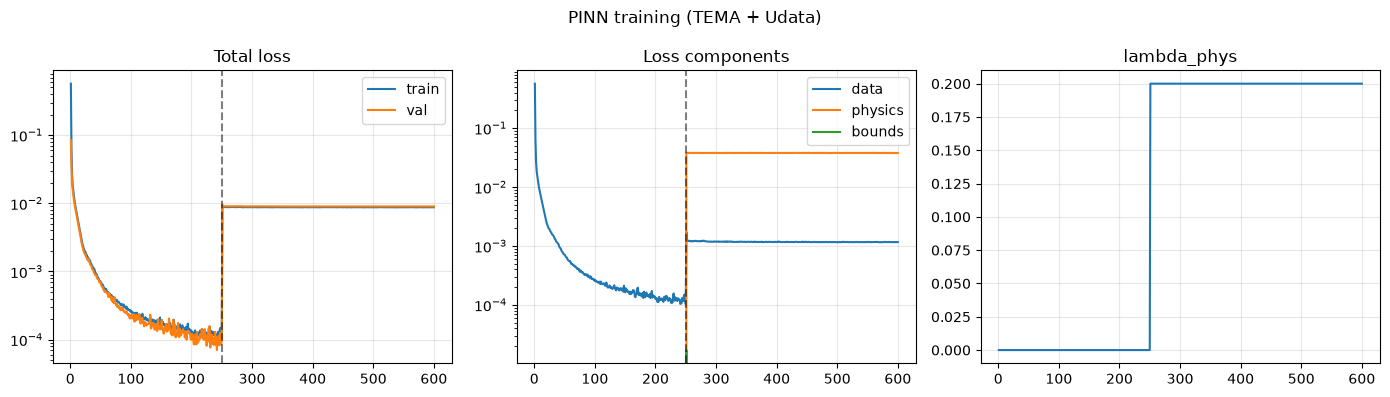

In [5]:
# Loss curves
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
ep = history["epoch"]
axes[0].plot(ep, history["train"], label="train")
axes[0].plot(ep, history["val"], label="val")
axes[0].axvline(WARMUP_EPOCHS, color="k", ls="--", alpha=0.5)
axes[0].set_title("Total loss"); axes[0].legend(); axes[0].set_yscale("log"); axes[0].grid(True, alpha=0.3)

axes[1].plot(ep, history["data"], label="data")
axes[1].plot(ep, history["phys"], label="physics")
axes[1].plot(ep, history["bound"], label="bounds")
axes[1].axvline(WARMUP_EPOCHS, color="k", ls="--", alpha=0.5)
axes[1].set_title("Loss components"); axes[1].legend(); axes[1].set_yscale("log"); axes[1].grid(True, alpha=0.3)

axes[2].plot(ep, history["lam"])
axes[2].set_title("lambda_phys"); axes[2].grid(True, alpha=0.3)
plt.suptitle("PINN training (TEMA + Udata)")
plt.tight_layout()
plt.show()


## 5. PINN predictions (test set)

In [6]:
@torch.no_grad()
def predict_physical(X_features_kgh):
    model.eval()
    Xs = x_scaler.transform(np.asarray(X_features_kgh, dtype=np.float64))
    y_s = model(to_tensor(Xs)).cpu().numpy()
    return y_scaler.inverse_transform(y_s)

Y_pred_train = predict_physical(X_train)
Y_pred_test = predict_physical(X_test)


## 6. PINN model prediction vs data (before clipping)

PINN outputs on the test set: `U` vs Udata, hot fluid outlet, cold fluid outlet.
This runs **before** the clip cell, so the cold fluid outlet shows the raw values.

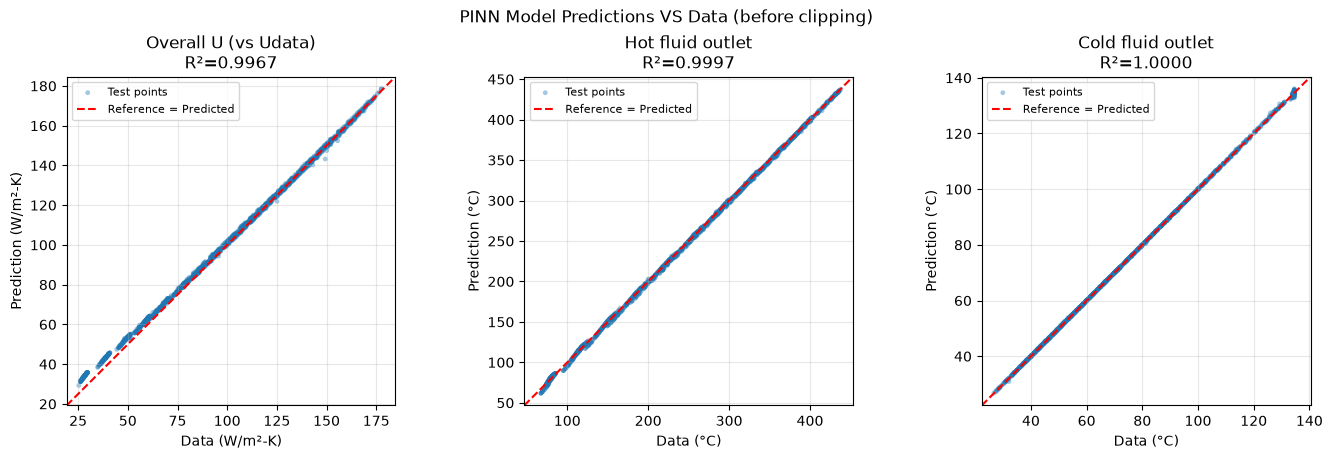

In [7]:
# PINN MODEL PREDICTION vs DATA (test set) — BEFORE clipping
# Points on the red dashed line (y = x) are perfect predictions.


def plot_pinn_vs_data(stage):
    """1x3 parity plots of the PINN: U vs Udata, hot and cold fluid outlets."""
    pairs = [
        (Y_test[:, 0], Y_pred_test[:, 0], "Overall U (vs Udata)", "W/m²-K"),
        (Y_test[:, 1], Y_pred_test[:, 1], "Hot fluid outlet", "°C"),
        (Y_test[:, 2], Y_pred_test[:, 2], "Cold fluid outlet", "°C"),
    ]

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
    for ax, (yt, yp, name, unit) in zip(axes, pairs):
        r2 = r2_score(yt, yp)

        ax.scatter(yt, yp, s=12, alpha=0.4, edgecolors="none", label="Test points")
        lo, hi = min(yt.min(), yp.min()), max(yt.max(), yp.max())
        pad = 0.04 * (hi - lo if hi > lo else 1.0)
        ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], "r--", lw=1.5, label="Reference = Predicted")
        ax.set_xlim(lo - pad, hi + pad)
        ax.set_ylim(lo - pad, hi + pad)
        ax.set_xlabel(f"Data ({unit})")
        ax.set_ylabel(f"Prediction ({unit})")
        ax.set_title(f"{name}\nR²={r2:.4f}")
        ax.grid(True, alpha=0.3)
        ax.legend(loc="upper left", fontsize=8)
        ax.set_aspect("equal", adjustable="box")

    plt.suptitle(f"PINN Model Predictions VS Data ({stage})")
    plt.tight_layout()
    plt.show()


plot_pinn_vs_data("before clipping")

In [8]:
# =====================================================================
# CLIP WATER OUTLET AT SATURATION TEMPERATURE  (separate post-processing)
# =====================================================================
# In data.csv the water outlet never goes above ~134.6 °C: at the water-side
# pressure (~3 bar) the water starts boiling, and extra heat goes into
# evaporation instead of raising the temperature.
# The PINN can still predict values above this. Here we simply cap the
# predicted water outlet (column 2 = Twout) at T_SAT_WATER.
# The trained PINN itself is NOT changed — delete/skip this cell to undo.

T_SAT_WATER = 134.6   # °C, max water outlet seen in data.csv

# Keep the original (unclipped) predictions for reference
Y_pred_train_raw = Y_pred_train.copy()
Y_pred_test_raw = Y_pred_test.copy()

# Cap the water outlet prediction at the saturation temperature
Y_pred_train[:, 2] = np.minimum(Y_pred_train_raw[:, 2], T_SAT_WATER)
Y_pred_test[:, 2] = np.minimum(Y_pred_test_raw[:, 2], T_SAT_WATER)

n_clipped = int((Y_pred_test_raw[:, 2] > T_SAT_WATER).sum())
print(f"Clipped {n_clipped} of {len(Y_pred_test)} test rows at T_sat = {T_SAT_WATER} °C")
# ====================== END OF CLIP SECTION ==========================


Clipped 88 of 1506 test rows at T_sat = 134.6 °C


## 7. PINN model prediction vs data (after clipping)

Same plot as section 6, after the clip cell (cold fluid outlet capped at `T_SAT_WATER`).

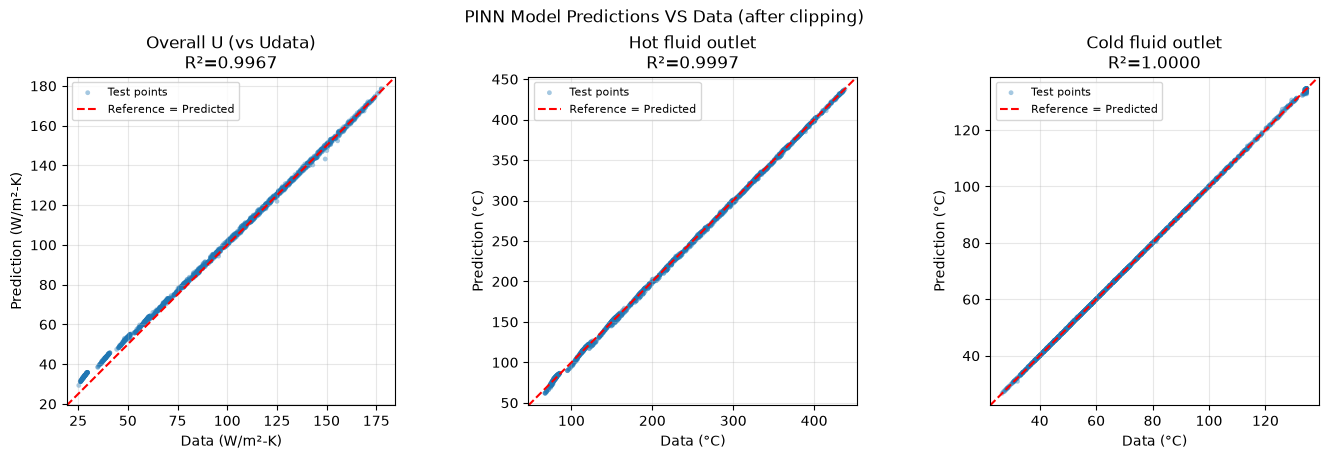

In [9]:
# PINN MODEL PREDICTION vs DATA (test set) — AFTER clipping
# Uses plot_pinn_vs_data from section 6.

plot_pinn_vs_data("after clipping")

## 8. Metrics and physics consistency (after clipping)

In [10]:
names = ["U (vs Udata)", "Taout", "Twout"]
units = ["W/m2-K", "C", "C"]
print("=" * 64)
print("  PINN vs Udata / DATASET")
print("=" * 64)
metrics = {}
for i, (name, unit) in enumerate(zip(names, units)):
    r2_tr = r2_score(Y_train[:, i], Y_pred_train[:, i])
    r2_te = r2_score(Y_test[:, i], Y_pred_test[:, i])
    mae = mean_absolute_error(Y_test[:, i], Y_pred_test[:, i])
    rmse = float(np.sqrt(mean_squared_error(Y_test[:, i], Y_pred_test[:, i])))
    metrics[name] = {"R2_train": r2_tr, "R2_test": r2_te, "MAE": mae, "RMSE": rmse}
    print(f"{name:14s} | Train R2={r2_tr:.4f} | Test R2={r2_te:.4f} | MAE={mae:.3f} {unit} | RMSE={rmse:.3f}")
print("=" * 64)


  PINN vs Udata / DATASET
U (vs Udata)   | Train R2=0.9969 | Test R2=0.9967 | MAE=1.673 W/m2-K | RMSE=2.294
Taout          | Train R2=0.9997 | Test R2=0.9997 | MAE=1.305 C | RMSE=1.795
Twout          | Train R2=0.9999 | Test R2=1.0000 | MAE=0.092 C | RMSE=0.179


In [11]:
# Physics consistency vs TEMA rating (test set)
U_p, Tao_p, Two_p = Y_pred_test[:, 0], Y_pred_test[:, 1], Y_pred_test[:, 2]
U_ref, Ta_ref, Tw_ref = [], [], []
for i in range(len(Y_pred_test)):
    r = rate_shell_and_tube_1_2(
        float(X_test[i, 2]), float(M_test[i, 0]), float(X_test[i, 3]), float(M_test[i, 1])
    )
    U_ref.append(r["U_phys"]); Ta_ref.append(r["T_air_out_phys"]); Tw_ref.append(r["T_water_out_phys"])
U_ref, Ta_ref, Tw_ref = map(np.asarray, (U_ref, Ta_ref, Tw_ref))
print("Physics consistency (PINN vs TEMA rating) on TEST")
print(f"  median |U_PINN - U_phys|/|U_phys| : {np.median(np.abs(U_p - U_ref) / np.clip(np.abs(U_ref), 1, None) * 100):.2f} %")
print(f"  median |Taout_PINN - Ta_phys|     : {np.median(np.abs(Tao_p - Ta_ref)):.3f} C")
print(f"  median |Twout_PINN - Tw_phys|     : {np.median(np.abs(Two_p - Tw_ref)):.3f} C")
print(f"  R2(U)={r2_score(U_ref, U_p):.4f}  R2(Ta)={r2_score(Ta_ref, Tao_p):.4f}  R2(Tw)={r2_score(Tw_ref, Two_p):.4f}")


Physics consistency (PINN vs TEMA rating) on TEST
  median |U_PINN - U_phys|/|U_phys| : 13.43 %
  median |Taout_PINN - Ta_phys|     : 6.205 C
  median |Twout_PINN - Tw_phys|     : 3.376 C
  R2(U)=0.7368  R2(Ta)=0.9310  R2(Tw)=0.7190


## 9. Feature importance (PINN)

A neural network has no built-in feature importance, so we use **permutation importance** on the test set:
shuffle one input column at a time and measure how much the test R² drops for each output (`U`, `Taout`, `Twout`).
A bigger drop means the PINN relies more on that input.

Permutation importance (mean test R² drop):
            U (vs Udata)  Hot fluid outlet  Cold fluid outlet
m_air             1.8724            0.0544             0.6021
m_water           0.0741            0.0025             0.5935
T_air_in          0.0275            1.9426             1.0451
T_water_in        0.0006            0.0005             0.0422


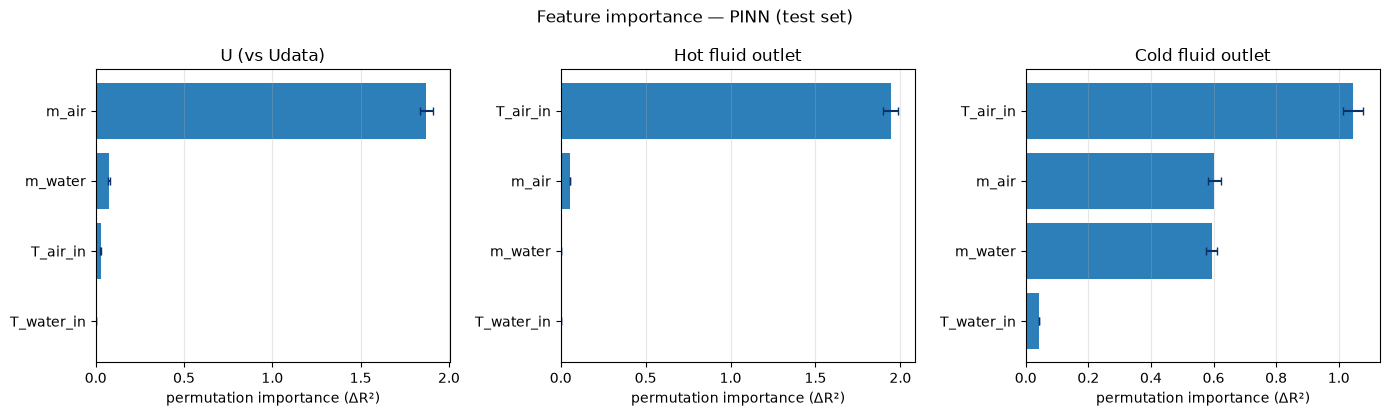

In [12]:
# FEATURE IMPORTANCE of the PINN (test set)
# Permutation importance: shuffle one input at a time -> drop in test R²
# Uses the raw PINN predictions (the Twout clip cell is not applied here).

feature_labels = np.array(["m_air", "m_water", "T_air_in", "T_water_in"])
output_names = ["U (vs Udata)", "Hot fluid outlet", "Cold fluid outlet"]
N_REPEATS = 20

rng = np.random.RandomState(42)
base_pred = predict_physical(X_test)
base_r2 = np.array([r2_score(Y_test[:, j], base_pred[:, j]) for j in range(3)])

n_feat = X_test.shape[1]
imp = np.zeros((3, n_feat))   # mean R² drop  [output, feature]
err = np.zeros((3, n_feat))   # std of R² drop

for f in range(n_feat):
    drops = np.zeros((N_REPEATS, 3))
    for r in range(N_REPEATS):
        X_perm = X_test.copy()
        X_perm[:, f] = rng.permutation(X_perm[:, f])
        pred = predict_physical(X_perm)
        drops[r] = base_r2 - np.array([r2_score(Y_test[:, j], pred[:, j]) for j in range(3)])
    imp[:, f] = drops.mean(axis=0)
    err[:, f] = drops.std(axis=0)

imp_df = pd.DataFrame(imp.T, index=feature_labels, columns=output_names)
print("Permutation importance (mean test R² drop):")
print(imp_df.round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for j, ax in enumerate(axes):
    order = np.argsort(imp[j])
    ax.barh(
        feature_labels[order],
        imp[j, order],
        xerr=err[j, order],
        color="#2c7fb8",
        ecolor="#08306b",
        capsize=3,
    )
    ax.set_xlabel("permutation importance (ΔR²)")
    ax.set_title(output_names[j])
    ax.grid(True, axis="x", alpha=0.3)

plt.suptitle("Feature importance — PINN (test set)")
plt.tight_layout()
plt.show()


## 10. Digital Twin


In [13]:
def digital_twin(m_air_kgh, m_water_kgh, T_air_in, T_water_in,
                 P_air_in_atm=P_AIR_IN / ATM, P_water_in_atm=P_WATER_IN / ATM, verbose=True):
    """PINN digital twin. Flows in kg/h, temperatures in C, pressures in atm (absolute).
    The PINN inputs are flows + temperatures only; pressure goes into the TEMA physics reference."""
    x = np.array([[m_air_kgh, m_water_kgh, T_air_in, T_water_in]], dtype=np.float64)
    U, Taout, Twout = predict_physical(x)[0]
    ma, mw = m_air_kgh / 3600.0, m_water_kgh / 3600.0
    _, _, cp_a, _, _ = get_air_properties(0.5 * (T_air_in + Taout))
    Q_kW = ma * cp_a * (T_air_in - Taout) / 1000.0
    phys = rate_shell_and_tube_1_2(
        T_air_in, ma, T_water_in, mw,
        P_air_in=P_air_in_atm * ATM, P_water_in=P_water_in_atm * ATM,
    )
    out = {
        "U_pred": float(U),
        "T_air_out": float(Taout),
        "T_water_out": float(Twout),
        "Q_kW": float(Q_kW),
        "U_phys": phys["U_phys"],
        "T_air_out_phys": phys["T_air_out_phys"],
        "T_water_out_phys": phys["T_water_out_phys"],
    }
    if verbose:
        print("==========================================")
        print("  DIGITAL TWIN — PINN (TEMA + Udata)")
        print("==========================================")
        print("INPUTS")
        print(f"  Air mass flow   : {m_air_kgh:.1f} kg/h ({ma:.4f} kg/s)")
        print(f"  Water mass flow : {m_water_kgh:.1f} kg/h ({mw:.4f} kg/s)")
        print(f"  Air inlet       : {T_air_in:.2f} C")
        print(f"  Water inlet     : {T_water_in:.2f} C")
        print(f"  Air inlet press.: {P_air_in_atm:.2f} atm ({P_air_in_atm * ATM / 1000.0:.2f} kPa)")
        print(f"  Water inlet pr. : {P_water_in_atm:.2f} atm ({P_water_in_atm * ATM / 1000.0:.2f} kPa)")
        print("OUTPUTS (PINN)")
        print(f"  U               : {out['U_pred']:.2f} W/m2-K")
        print(f"  Air outlet      : {out['T_air_out']:.2f} C")
        print(f"  Water outlet    : {out['T_water_out']:.2f} C")
        print(f"  Duty            : {out['Q_kW']:.2f} kW")
        print("TEMA physics reference")
        print(f"  U_phys          : {out['U_phys']:.2f} W/m2-K")
        print(f"  Taout_phys      : {out['T_air_out_phys']:.2f} C")
        print(f"  Twout_phys      : {out['T_water_out_phys']:.2f} C")
    return out

# Example
_ = digital_twin(10000, 10000, 100, 25)


  DIGITAL TWIN — PINN (TEMA + Udata)
INPUTS
  Air mass flow   : 10000.0 kg/h (2.7778 kg/s)
  Water mass flow : 10000.0 kg/h (2.7778 kg/s)
  Air inlet       : 100.00 C
  Water inlet     : 25.00 C
  Air inlet press.: 1.50 atm (151.99 kPa)
  Water inlet pr. : 2.00 atm (202.65 kPa)
OUTPUTS (PINN)
  U               : 29.32 W/m2-K
  Air outlet      : 63.82 C
  Water outlet    : 30.94 C
  Duty            : 101.40 kW
TEMA physics reference
  U_phys          : 39.23 W/m2-K
  Taout_phys      : 60.08 C
  Twout_phys      : 34.65 C


In [14]:
# --- USER INPUT: change values and re-run ---
user_m_air_kgh = 50000
user_m_water_kgh = 30000
user_T_air_in = 200.0
user_T_water_in = 30.0
user_P_air_in_atm = 1.5
user_P_water_in_atm = 2.0

_ = digital_twin(
    user_m_air_kgh, user_m_water_kgh, user_T_air_in, user_T_water_in,
    P_air_in_atm=user_P_air_in_atm, P_water_in_atm=user_P_water_in_atm,
)


  DIGITAL TWIN — PINN (TEMA + Udata)
INPUTS
  Air mass flow   : 50000.0 kg/h (13.8889 kg/s)
  Water mass flow : 30000.0 kg/h (8.3333 kg/s)
  Air inlet       : 200.00 C
  Water inlet     : 30.00 C
  Air inlet press.: 1.50 atm (151.99 kPa)
  Water inlet pr. : 2.00 atm (202.65 kPa)
OUTPUTS (PINN)
  U               : 95.76 W/m2-K
  Air outlet      : 145.20 C
  Water outlet    : 51.36 C
  Duty            : 771.53 kW
TEMA physics reference
  U_phys          : 101.54 W/m2-K
  Taout_phys      : 144.13 C
  Twout_phys      : 52.62 C


## Summary

| Item | Choice |
|------|--------|
| Data | `Serial Model/data.csv` |
| Geometry | TEMA Type A, 160 tubes, L=6 m, triangular `De` |
| U target | **Udata** via LMTD |
| Inlet pressure | air 1.5 atm, water 2 atm (fluid properties) |
| Network | MLP 4→128→128→64→3 (SiLU) |
| Loss | data + `λ_phys=0.2` physics + `λ_bnd=0.02` bounds |
| Outputs | `U`, `Taout`, `Twout` |

**Note:** If `Udata` and film `U_phys` disagree, physics loss may plateau while data fit stays strong — that is expected with this dual objective.
